
## Detección de Outliers en un Dataset de Spotify 

En este proyecto se analizará un conjunto de datos de canciones de Spotify para identificar valores atípicos (*outliers*) mediante técnicas estadísticas y algoritmos de Machine Learning, como el rango intercuartílico (IQR) e Isolation Forest.


In [3]:
# 1. Importación de librerías y carga de datos

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest

# Cargar el dataset
df = pd.read_csv("data.csv")

# Mostrar las primeras 5 filas
df.head()

,Unnamed: 0,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,target,song_title,artist
0,0,0.0102,0.833,204600,0.434,0.021900,2,0.1650,-8.795,1,0.4310,150.062,4.0,0.286,1,Mask Off,Future
1,1,0.1990,0.743,326933,0.359,0.006110,1,0.1370,-10.401,1,0.0794,160.083,4.0,0.588,1,Redbone,Childish Gambino
2,2,0.0344,0.838,185707,0.412,0.000234,2,0.1590,-7.148,1,0.2890,75.044,4.0,0.173,1,Xanny Family,Future
3,3,0.6040,0.494,199413,0.338,0.510000,5,0.0922,-15.236,1,0.0261,86.468,4.0,0.230,1,Master Of None,Beach House
4,4,0.1800,0.678,392893,0.561,0.512000,5,0.4390,-11.648,0,0.0694,174.004,4.0,0.904,1,Parallel Lines,Junior Boys


In [4]:
# 2. Exploración inicial del dataset

# Dimensiones del dataset
print("Dimensiones:", df.shape)

# Información de las variables
df.info()

# Valores faltantes
print("\nValores faltantes:")
print(df.isnull().sum())

Dimensiones: (2017, 17)
<class 'pandas.DataFrame'>
RangeIndex: 2017 entries, 0 to 2016
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        2017 non-null   int64  
 1   acousticness      2017 non-null   float64
 2   danceability      2017 non-null   float64
 3   duration_ms       2017 non-null   int64  
 4   energy            2017 non-null   float64
 5   instrumentalness  2017 non-null   float64
 6   key               2017 non-null   int64  
 7   liveness          2017 non-null   float64
 8   loudness          2017 non-null   float64
 9   mode              2017 non-null   int64  
 10  speechiness       2017 non-null   float64
 11  tempo             2017 non-null   float64
 12  time_signature    2017 non-null   float64
 13  valence           2017 non-null   float64
 14  target            2017 non-null   int64  
 15  song_title        2017 non-null   str    
 16  artist            2017 non-nu

## Detección de valores atípicos mediante IQR

Se utiliza el rango intercuartílico (IQR) para identificar valores
que se encuentran fuera de los límites estadísticos de cada variable.

In [5]:
# Seleccionar variables numéricas continuas
variables = [
    "acousticness", "danceability", "duration_ms",
    "energy", "instrumentalness", "liveness",
    "loudness", "speechiness", "tempo", "valence"
]

# Calcular cuartiles e IQR
Q1 = df[variables].quantile(0.25)
Q3 = df[variables].quantile(0.75)
IQR = Q3 - Q1

# Calcular límites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Identificar outliers
outliers = (
    (df[variables] < limite_inferior) |
    (df[variables] > limite_superior)
)

# Resumen de resultados
resumen = pd.DataFrame({
    "Outliers": outliers.sum(),
    "Porcentaje (%)": (outliers.mean() * 100).round(2)
})

display(resumen.sort_values("Outliers", ascending=False))

,Outliers,Porcentaje (%)
instrumentalness,416,20.62
speechiness,209,10.36
acousticness,194,9.62
duration_ms,141,6.99
liveness,126,6.25
loudness,105,5.21
energy,54,2.68
tempo,15,0.74
danceability,12,0.59
valence,0,0.00


## Visualización de outliers

Se utilizan diagramas de caja (boxplots) para visualizar
la distribución de los datos y los valores atípicos.

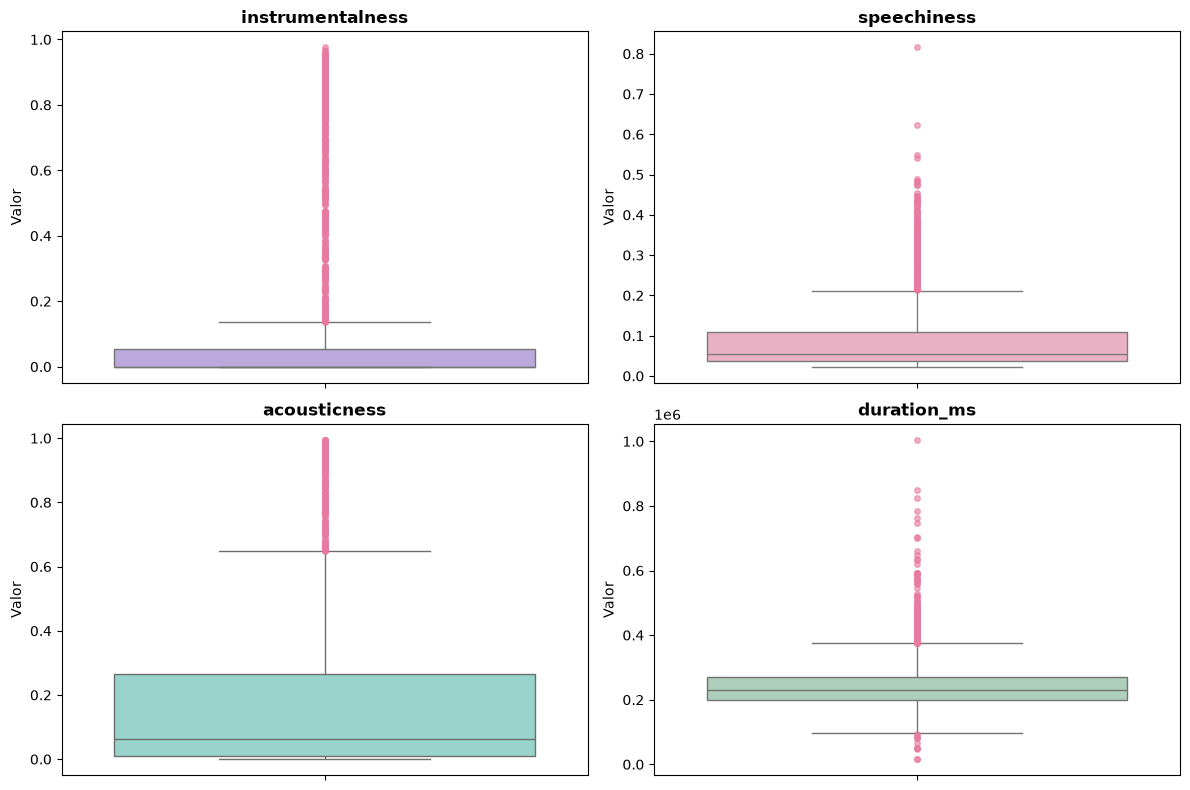

In [7]:
# Variables con mayor cantidad de outliers
columnas = [
    "instrumentalness",
    "speechiness",
    "acousticness",
    "duration_ms"
]

# Paleta de colores
colores = ["#B8A1E3", "#F4A7C1", "#8EDDD3", "#A8D5BA"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for i, (ax, columna) in enumerate(zip(axes.flat, columnas)):
    sns.boxplot(
        y=df[columna],
        ax=ax,
        color=colores[i],
        flierprops={
            "marker": "o",
            "markerfacecolor": "#E879A0",
            "markeredgecolor": "#E879A0",
            "markersize": 4,
            "alpha": 0.6
        }
    )
    ax.set_title(columna, fontsize=12, fontweight="bold")
    ax.set_ylabel("Valor")

plt.tight_layout()
plt.show()

## Detección de outliers mediante Isolation Forest

Se aplica el algoritmo Isolation Forest para identificar
canciones con características musicales atípicas.

In [8]:
# Crear modelo Isolation Forest
modelo = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=42
)

# Entrenar y detectar anomalías
df["outlier_iforest"] = modelo.fit_predict(df[variables])

# Contar resultados
normales = (df["outlier_iforest"] == 1).sum()
atipicos = (df["outlier_iforest"] == -1).sum()

print("Canciones normales:", normales)
print("Canciones atípicas:", atipicos)
print("Porcentaje de outliers:", round(atipicos / len(df) * 100, 2), "%")

Canciones normales: 1654
Canciones atípicas: 363
Porcentaje de outliers: 18.0 %


## Análisis de asimetría y posibles transformaciones

Se analiza la asimetría de las variables para determinar
si es conveniente aplicar transformaciones a los datos.

In [9]:
# Calcular la asimetría de las variables
asimetria = df[variables].skew().round(2)

# Ordenar por mayor asimetría absoluta
asimetria = asimetria.reindex(
    asimetria.abs().sort_values(ascending=False).index
)

display(asimetria)

duration_ms         2.50
speechiness         2.31
loudness           -2.23
instrumentalness    1.95
liveness            1.95
acousticness        1.66
energy             -0.91
tempo               0.44
danceability       -0.42
valence             0.08
dtype: float64

## Transformación de variables

Se aplican transformaciones logarítmicas y Yeo-Johnson
para reducir la asimetría de algunas variables,
conservando los datos originales.

In [10]:
from sklearn.preprocessing import PowerTransformer

# Crear una copia para conservar los datos originales
df_transformado = df.copy()

# Transformación logarítmica
df_transformado["duration_log"] = np.log1p(df["duration_ms"])

# Transformación Yeo-Johnson
columnas_yj = ["speechiness", "loudness"]

transformador = PowerTransformer(
    method="yeo-johnson",
    standardize=False
)

df_transformado[["speechiness_yj", "loudness_yj"]] = (
    transformador.fit_transform(df[columnas_yj])
)

# Comparar asimetría antes y después
comparacion = pd.DataFrame({
    "Original": [
        df["duration_ms"].skew(),
        df["speechiness"].skew(),
        df["loudness"].skew()
    ],
    "Transformada": [
        df_transformado["duration_log"].skew(),
        df_transformado["speechiness_yj"].skew(),
        df_transformado["loudness_yj"].skew()
    ]
}, index=["duration_ms", "speechiness", "loudness"])

display(comparacion.round(2))

,Original,Transformada
duration_ms,2.50,-0.33
speechiness,2.31,0.56
loudness,-2.23,0.02



## 8. Conclusiones

### 1. ¿Tengo datos atípicos? ¿En qué variables?

Sí. Al aplicar el método IQR a las 2,017 canciones del dataset, encontré valores atípicos en 9 de las 10 variables analizadas.

Las variables con mayor porcentaje de outliers fueron:

- **Instrumentalness:** 416 valores (20.62 %).
- **Speechiness:** 209 valores (10.36 %).
- **Acousticness:** 194 valores (9.62 %).
- **Duration_ms:** 141 valores (6.99 %).

Por otro lado, Isolation Forest identificó 363 canciones atípicas, equivalentes al 18 % del dataset, considerando varias características musicales simultáneamente.

### 2. ¿Qué haría con ellos?

Considero que no sería conveniente eliminar los outliers automáticamente, ya que pueden representar características reales de las canciones, como duraciones inusuales o niveles elevados de instrumentalidad.

Primero investigaría si corresponden a errores de registro o a características musicales válidas. Conservaría los datos correctos y evaluaría su impacto dependiendo del análisis o modelo que quisiera desarrollar.

### 3. ¿Qué transformación haría con ellos?

Apliqué transformaciones para reducir la asimetría de tres variables:

- **Duration_ms:** transformación logarítmica. Su asimetría pasó de 2.50 a -0.33.
- **Speechiness:** transformación Yeo-Johnson. Su asimetría pasó de 2.31 a 0.56.
- **Loudness:** transformación Yeo-Johnson. Su asimetría pasó de -2.23 a 0.02.

Los resultados muestran una reducción considerable de la asimetría, por lo que estas transformaciones podrían ser útiles para determinados modelos de Machine Learning.

En conclusión, los outliers no necesariamente representan errores. Su tratamiento debe depender del contexto, las características de los datos y el objetivo del análisis.

### Dataset utilizado

**Spotify Song Attributes — Kaggle**

https://www.kaggle.com/datasets/geomack/spotifyclassification
